In [1]:
import torch
import matplotlib.pyplot as plt
from ddpm.masks.rad_masks import(box, channel_strip, time_strip, oriented_band, anisotropic_perlin, random_rad_mask)

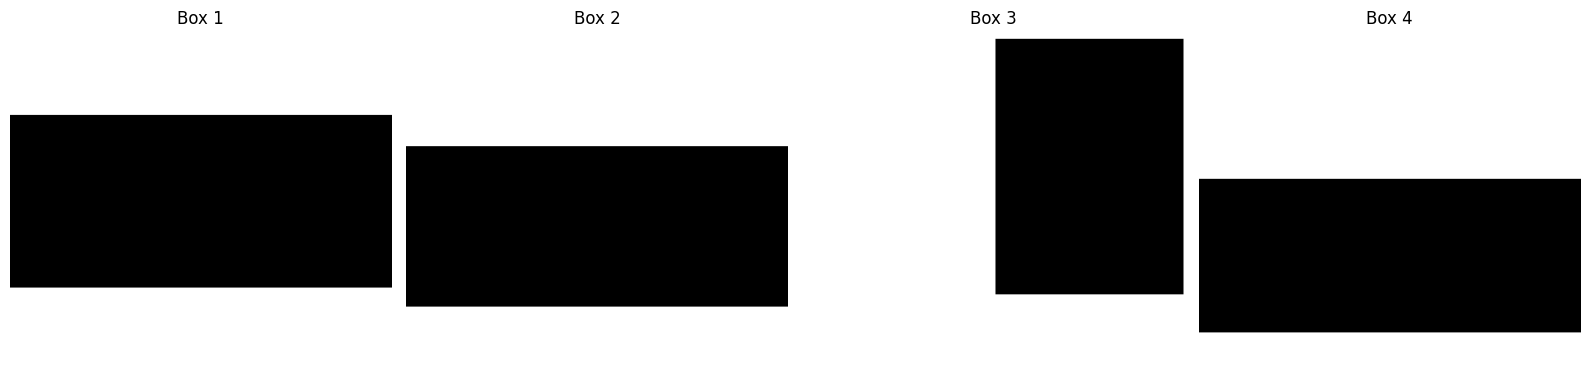

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
B=4
H=256
W=512
masks = box(B=B, H=H, W=W, device= device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Box {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

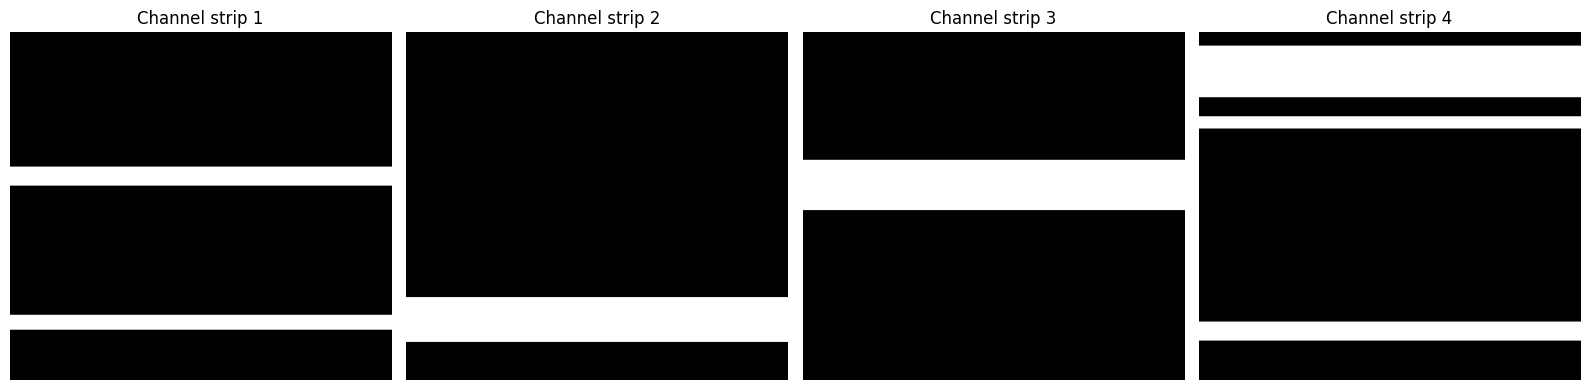

In [95]:
masks = channel_strip(B, H, W, device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Channel strip {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

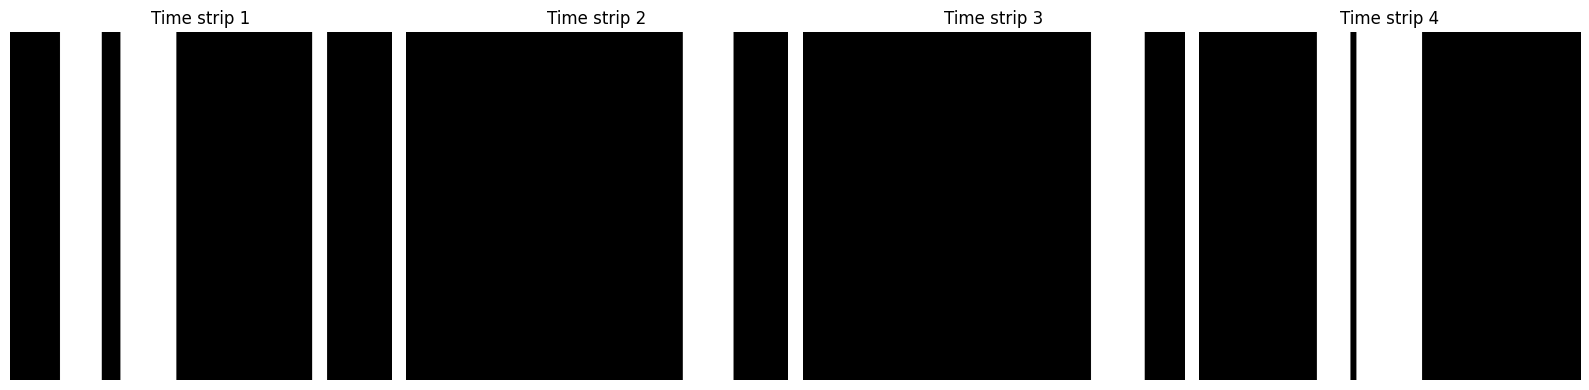

In [96]:
masks = time_strip(B, H, W, device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Time strip {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

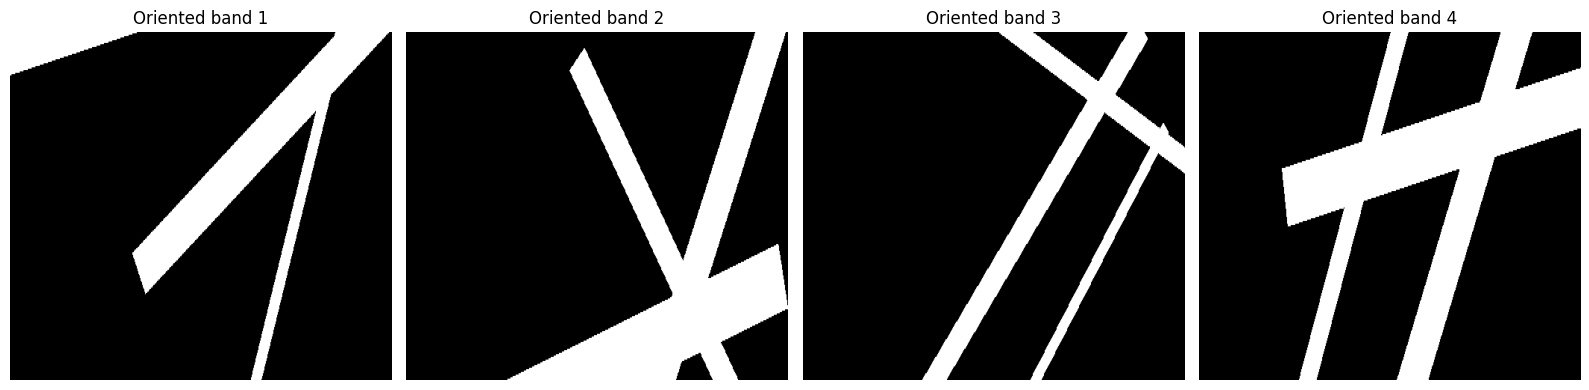

In [102]:
masks = oriented_band(B, H, W,thickness_range=(0.04,0.20), length_range=(0.60, 1.40), count_range=(1,3), device=device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Oriented band {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [87]:
import importlib
from ddpm.masks import rad_masks as masks
importlib.reload(masks)

<module 'ddpm.masks.rad_masks' from '/home/islem.dhouioui/ddpm/src/ddpm/masks/rad_masks.py'>

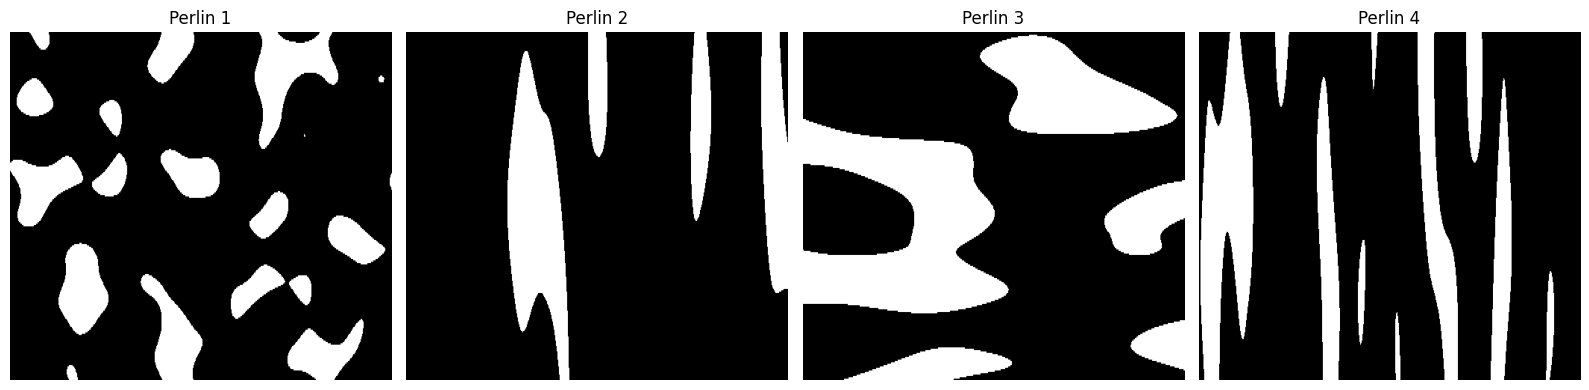

In [103]:
masks = anisotropic_perlin(B, H, W, device)

fig, axes = plt.subplots(1, B, figsize=(16, 4))

for i in range(B):
    axes[i].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i].set_title(f"Perlin {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [3]:
from pathlib import Path
from torch.utils.data import DataLoader
from ddpm.data.das_dataset import DasDataset

In [4]:
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
train_files_earthquake = [das_data/"train_1001.h5"]
test_files_earthquake = [das_data/"test_1001.h5"]

device= "cuda" if torch.cuda.is_available() else "cpu"

train_set_earthquake = DasDataset(train_files_earthquake)
test_set_earthquake = DasDataset(test_files_earthquake)
train_loader_earthquake = DataLoader(train_set_earthquake, batch_size=16, shuffle=True)
test_loader_earthquake = DataLoader(test_set_earthquake, batch_size=16, shuffle=False)

In [11]:
batch = next(iter(train_loader_earthquake))
x = batch.to(device)

B_vis = 4
x = x[:B_vis]

B, C, H, W = x.shape

masks = random_rad_mask(B=B, H=H, W=W, device=device)
masked_x = x* masks

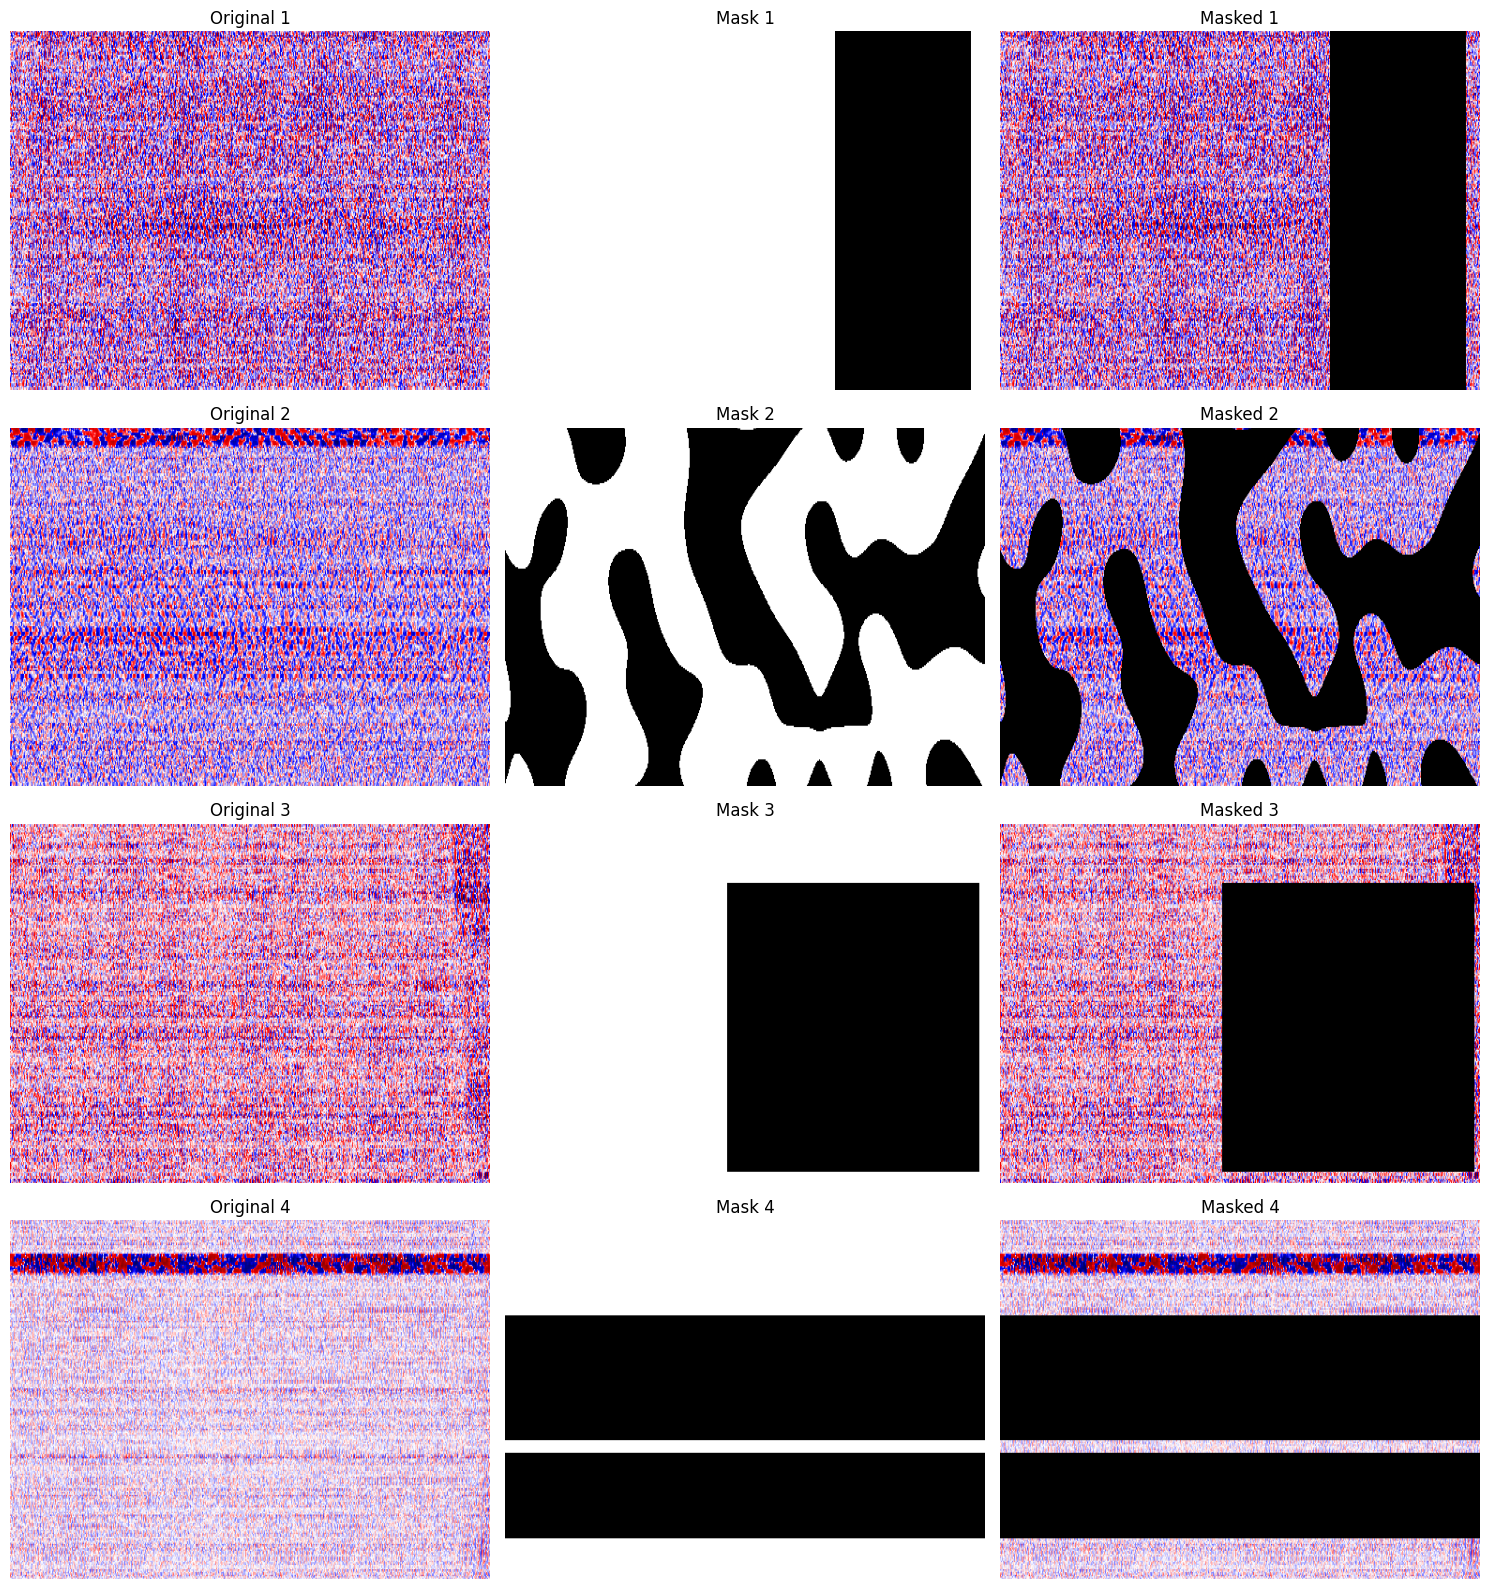

In [12]:
from matplotlib.colors import ListedColormap

black_mask = ListedColormap([(0, 0, 0, 0), (0, 0, 0, 1)])

fig, axes = plt.subplots(B_vis, 3, figsize=(15, 4 * B_vis))

for i in range(B_vis):
    axes[i, 0].imshow(x[i, 0].cpu(), aspect="auto", cmap="seismic")
    axes[i, 0].set_title(f"Original {i+1}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(masks[i, 0].cpu(), aspect="auto", cmap="gray")
    axes[i, 1].set_title(f"Mask {i+1}")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(x[i, 0].cpu(), aspect="auto", cmap="seismic")
    axes[i, 2].imshow((1 - masks[i, 0]).cpu(), aspect="auto", cmap=black_mask)
    axes[i, 2].set_title(f"Masked {i+1}")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
area_fraction = (1-masks).mean(dim=(1, 2, 3)).cpu()
print(area_fraction.tolist())

[0.5859375, 0.384765625, 0.124908447265625, 0.681640625]


In [ ]:
fractions = []

for _ in range(200):
    masks = random_rad_mask(B=16,H=256,W=512,device=device)
    fractions.extend((1-masks).mean(dim=(1, 2, 3)).cpu().tolist())

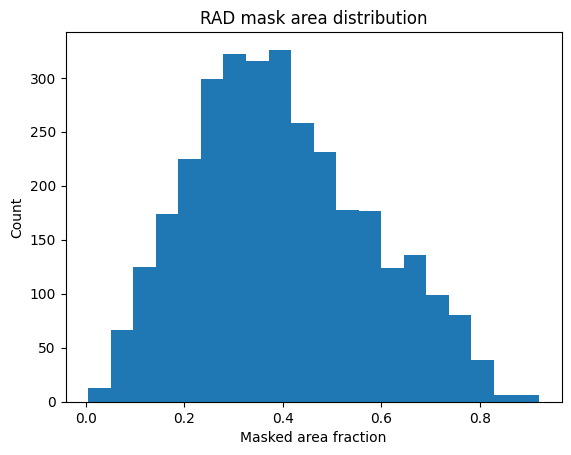

In [92]:
plt.hist(fractions, bins=20)
plt.xlabel("Masked area fraction")
plt.ylabel("Count")
plt.title("RAD mask area distribution")
plt.show()

In [79]:
print("min:", min(fractions))
print("max:", max(fractions))
print("mean:", sum(fractions) / len(fractions))

min: 0.0048828125
max: 0.884765625
mean: 0.364073314666748


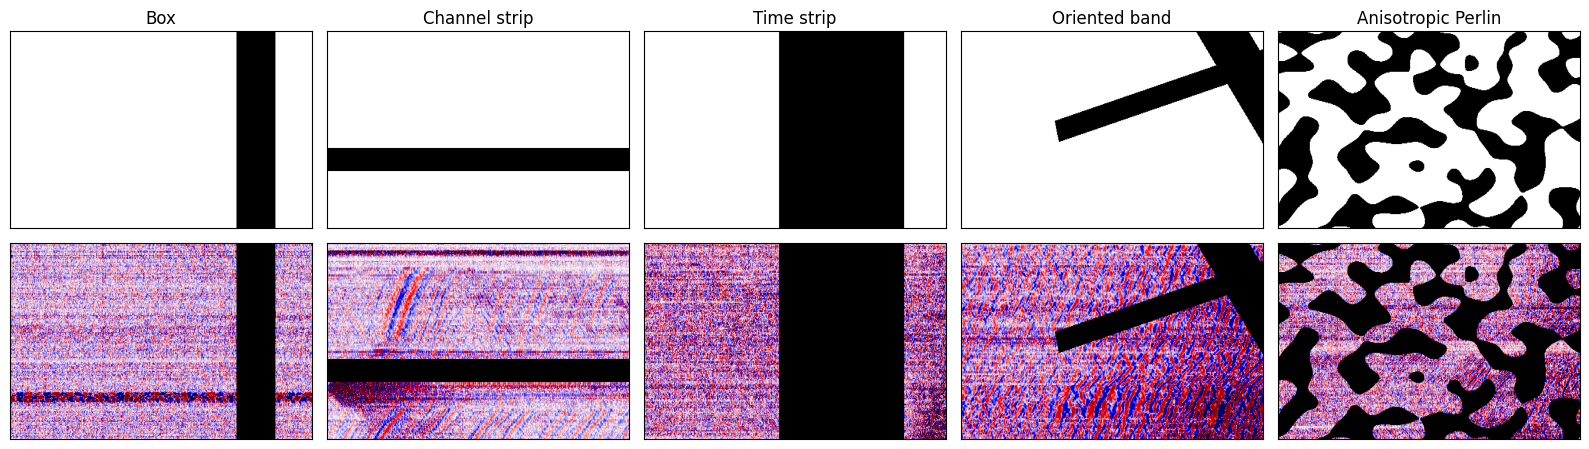

In [13]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ddpm.data.das_dataset import DasDataset
from ddpm.masks.rad_masks import box, channel_strip, time_strip, oriented_band, anisotropic_perlin

das_data = Path("/datasets/training/earthquake/share/SISSLE_south30")
test_set = DasDataset([das_data / "test_1001.h5"])

H, W = 256, 512
device = "cpu"
g = torch.Generator(device=device).manual_seed(3)

mask_types = [
    ("Box", box),
    ("Channel strip", channel_strip),
    ("Time strip", time_strip),
    ("Oriented band", oriented_band),
    ("Anisotropic Perlin", anisotropic_perlin),
]
patch_ids = [0, 10, 20, 30, 40]

cmap = plt.get_cmap("seismic").copy()
cmap.set_bad("black")

fig, axes = plt.subplots(2, 5, figsize=(16, 4.6))
for k, (name, fn) in enumerate(mask_types):
    m = fn(1, H, W, device, generator=g)[0, 0].numpy()
    x = test_set[patch_ids[k]].squeeze().numpy()
    v = np.percentile(np.abs(x), 99)

    axes[0, k].imshow(m, cmap="gray", vmin=0, vmax=1, aspect="auto")
    axes[0, k].set_title(name, fontsize=12)

    masked = np.ma.masked_where(m == 0, x)
    axes[1, k].imshow(masked, cmap=cmap, vmin=-v, vmax=v, aspect="auto")

for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig("rad_mask_examples.pdf", bbox_inches="tight")
plt.show()

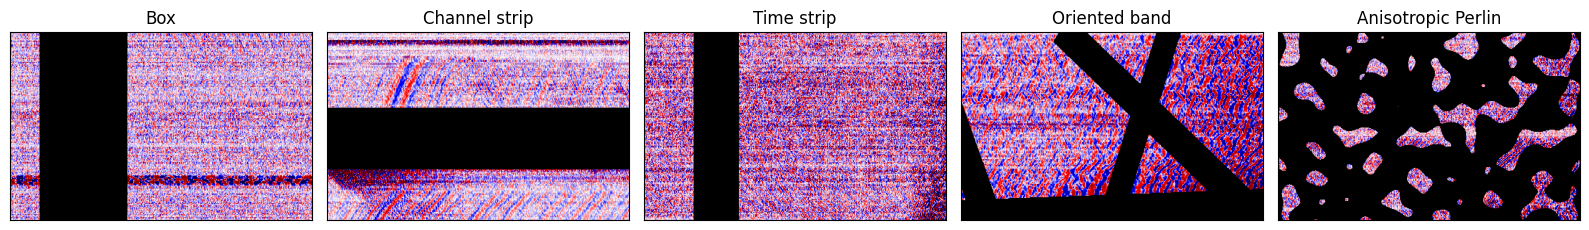

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(16, 2.4))
for k, (name, fn) in enumerate(mask_types):
    m = fn(1, H, W, device, generator=g)[0, 0].numpy()
    x = test_set[patch_ids[k]].squeeze().numpy()
    v = np.percentile(np.abs(x), 99)
    masked = np.ma.masked_where(m == 0, x)
    axes[k].imshow(masked, cmap=cmap, vmin=-v, vmax=v, aspect="auto")
    axes[k].set_title(name, fontsize=12)
    axes[k].set_xticks([])
    axes[k].set_yticks([])

plt.tight_layout()
plt.savefig("rad_mask_examples.pdf", bbox_inches="tight")
plt.show()

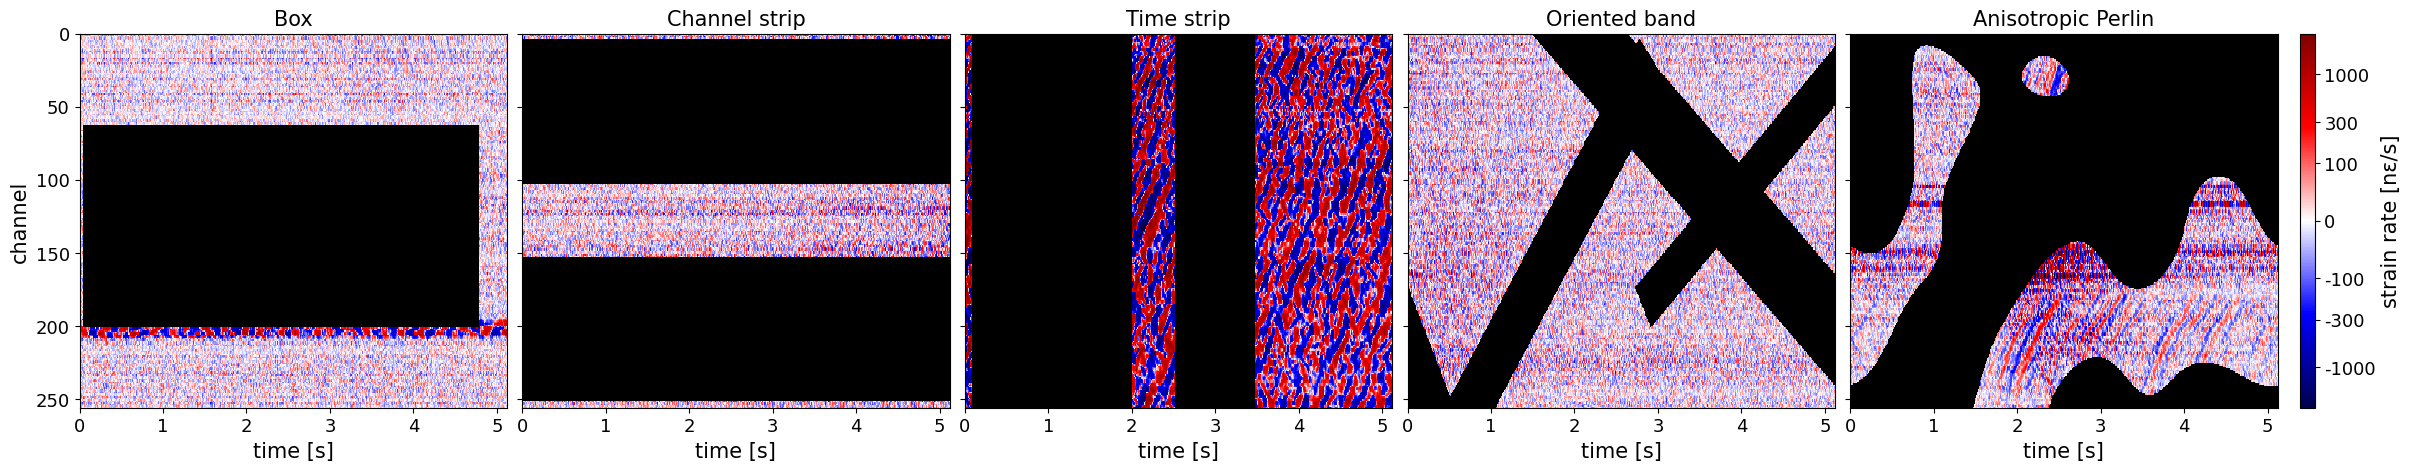

In [6]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from ddpm.data.das_dataset import DasDataset
from ddpm.masks.rad_masks import box, channel_strip, time_strip, oriented_band, anisotropic_perlin
from ddpm.paths import DAS_DATA, OUTPUTS

s_norm,A_max=50.0,12350.0
to_norm=lambda v: np.arcsinh(v/s_norm)/np.arcsinh(A_max/s_norm)
to_phys=lambda n: s_norm*np.sinh(n*np.arcsinh(A_max/s_norm))
plt.rcParams.update({"font.size":14,"axes.labelsize":15,"axes.titlesize":15,"xtick.labelsize":13,"ytick.labelsize":13})

fs=100
test_set=DasDataset([DAS_DATA/"test_1001.h5"])
patch_ids=[0,1,2,3,4]                                    
mask_fns=[("Box",box),("Channel strip",channel_strip),("Time strip",time_strip),
          ("Oriented band",oriented_band),("Anisotropic Perlin",anisotropic_perlin)]

g=torch.Generator().manual_seed(0)                       
panels=[]
for (title,fn),pid in zip(mask_fns,patch_ids):
    x=test_set[pid][0]
    m=fn(1,256,512,"cpu",generator=g)[0,0]
    xm=x.clone(); xm[m==0]=float("nan")
    panels.append((title,x,xm))

w=float(torch.quantile(torch.cat([p[1].abs().flatten() for p in panels]),0.995))  
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
fig,axes=plt.subplots(1,5,figsize=(24,4.6),sharey=True,constrained_layout=True)
for a,(title,x,xm) in zip(axes,panels):
    im_=a.imshow(xm,aspect="auto",cmap=cmap,vmin=-w,vmax=w,extent=[0,512/fs,256,0],interpolation="nearest")
    a.set_title(title); a.set_xlabel("time [s]")
axes[0].set_ylabel("channel")

cb=fig.colorbar(im_,ax=axes.ravel().tolist(),location="right",fraction=0.02,pad=0.01,aspect=25)
vmax_phys=to_phys(w)
cand=[0]+[sg*v for v in [10000,3000,1000,300,100,30,10] for sg in (1,-1) if v<=vmax_phys]
ticks=[]
for t in cand:
    if all(abs(to_norm(t)-to_norm(u))>=0.15*w for u in ticks): ticks.append(t)
ticks=sorted(ticks)
cb.set_ticks(to_norm(np.array(ticks,dtype=float))); cb.set_ticklabels([f"{t:g}" for t in ticks])
cb.set_label("strain rate [nε/s]")

fig.savefig(OUTPUTS/"rad_mask_types.pdf",bbox_inches="tight")
fig.savefig(OUTPUTS/"rad_mask_types.png",dpi=200,bbox_inches="tight")
plt.show()

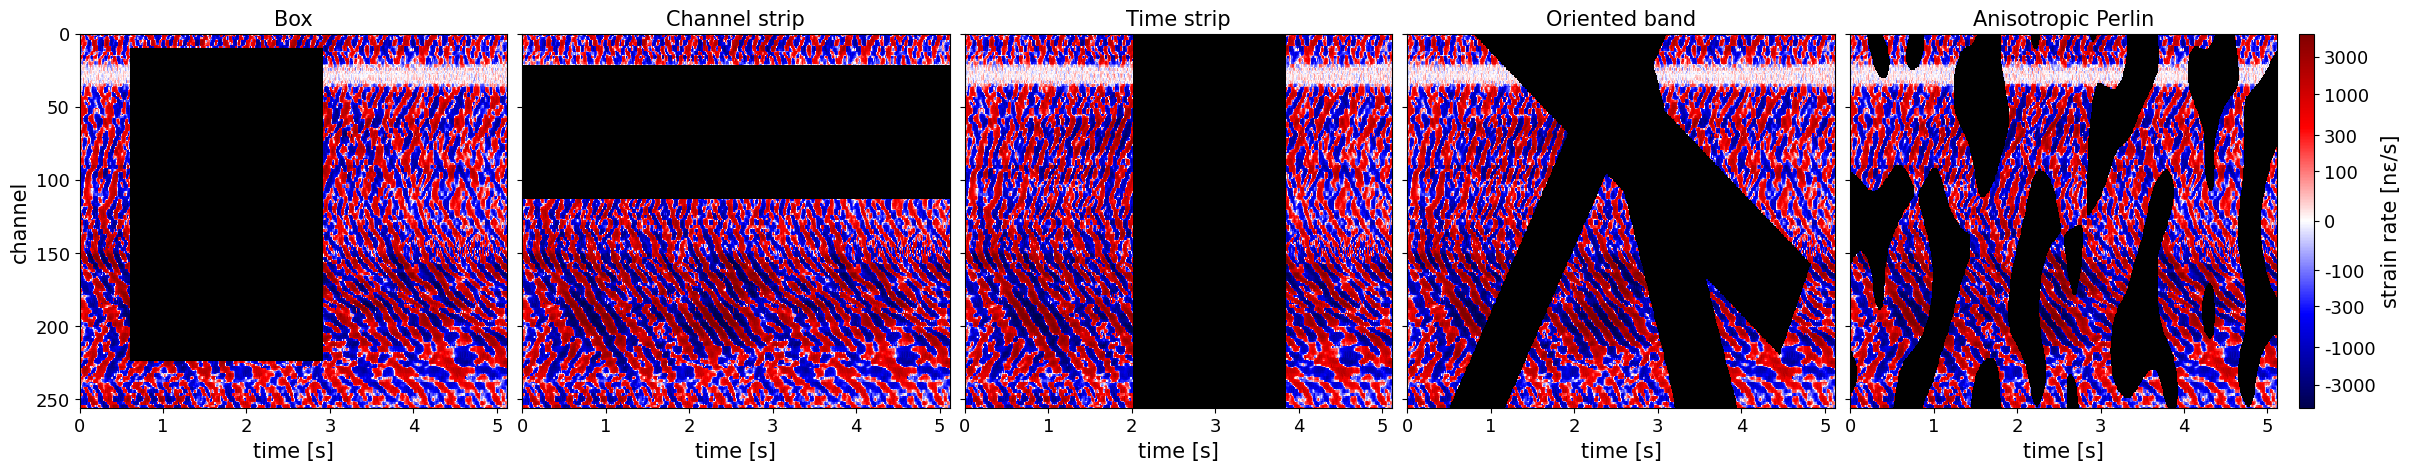

In [14]:
w=float(torch.quantile(torch.cat([p[1].abs().flatten() for p in panels]),0.995))
cmap=plt.get_cmap("seismic").copy(); cmap.set_bad("black")
fig,axes=plt.subplots(1,5,figsize=(24,4.6),sharey=True,constrained_layout=True)
for a,(title,x_,xm) in zip(axes,panels):
    im_=a.imshow(xm,aspect="auto",cmap=cmap,vmin=-w,vmax=w,extent=[0,512/fs,256,0],interpolation="nearest")
    a.set_title(title); a.set_xlabel("time [s]")
axes[0].set_ylabel("channel")

cb=fig.colorbar(im_,ax=axes.ravel().tolist(),location="right",fraction=0.02,pad=0.01,aspect=25)
vmax_phys=to_phys(w)
cand=[0]+[sg*v for v in [10000,3000,1000,300,100,30,10] for sg in (1,-1) if v<=vmax_phys]
ticks=[]
for t in cand:
    if all(abs(to_norm(t)-to_norm(u))>=0.15*w for u in ticks): ticks.append(t)
ticks=sorted(ticks)
cb.set_ticks(to_norm(np.array(ticks,dtype=float))); cb.set_ticklabels([f"{t:g}" for t in ticks])
cb.set_label("strain rate [nε/s]")

fig.savefig(OUTPUTS/"rad_mask_types.pdf",bbox_inches="tight")
fig.savefig(OUTPUTS/"rad_mask_types.png",dpi=200,bbox_inches="tight")
plt.show()